# Otimizacao de Hiperparametros com Algoritmo Genetico

Este notebook executa a Fase 2 sobre a Arvore de Decisao do projeto. O algoritmo genetico procura hiperparametros melhores usando apenas o conjunto de treino, por validacao cruzada. O conjunto de teste fica reservado para a comparacao final.

> A execucao completa pode levar alguns minutos, pois cada individuo e avaliado em tres dobras de validacao cruzada.

## 1. Imports e configuracao do projeto

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.tree import DecisionTreeClassifier

RAIZ_PROJETO = Path.cwd().resolve()
if not (RAIZ_PROJETO / 'src').exists():
    RAIZ_PROJETO = RAIZ_PROJETO.parent

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

from src.dados import preparar_dados
from src.experimentos import CONFIGURACOES_PADRAO, executar_experimentos

DIRETORIO_RESULTADOS = RAIZ_PROJETO / 'resultados'
DIRETORIO_RESULTADOS.mkdir(exist_ok=True)
print(f'Raiz do projeto: {RAIZ_PROJETO}')

Raiz do projeto: D:\Estudos\IA\fiap-tech-chalange-2-ia-para-devs


## 2. Preparacao dos dados

A mesma limpeza usada na modelagem inicial e aplicada. A imputacao e calculada usando apenas o conjunto de treino.

In [7]:
CAMINHO_AMOSTRA = RAIZ_PROJETO / 'data' / 'samples' / 'VIOLBR25_amostra_50000.csv'
dados = preparar_dados(CAMINHO_AMOSTRA)
X_train, X_test = dados.X_train, dados.X_test
y_train, y_test = dados.y_train, dados.y_test

print(f'Formato de treino: {X_train.shape}')
print(f'Formato de teste: {X_test.shape}')
print(f'Colunas removidas: {dados.colunas_removidas}')
display(pd.DataFrame({
    'treino': y_train.value_counts().sort_index(),
    'teste': y_test.value_counts().sort_index(),
}))

Formato de treino: (40000, 31)
Formato de teste: (10000, 31)
Colunas removidas: ['NU_IDADE_N']


,treino,teste
OUT_VEZES,,
0,18073,4518
1,21927,5482


## 3. Modelo-base

Este e o modelo original: Arvore de Decisao com `max_depth=5`. Ele sera comparado no mesmo conjunto de teste reservado.

In [8]:
modelo_base = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo_base.fit(X_train, y_train)
previsoes_base = modelo_base.predict(X_test)

resultado_base = {
    'experimento': 'Arvore-base',
    'accuracy_teste': accuracy_score(y_test, previsoes_base),
    'recall_teste': recall_score(y_test, previsoes_base, zero_division=0),
    'f1_teste': f1_score(y_test, previsoes_base, zero_division=0),
    'max_depth': 5,
}
pd.DataFrame([resultado_base])

,experimento,accuracy_teste,recall_teste,f1_teste,max_depth
0,Arvore-base,0.6271,0.541043,0.614015,5


## 4. Configuracoes do algoritmo genetico

Os tres experimentos mudam tamanho da populacao, numero de geracoes e taxa de mutacao. A funcao fitness combina 70% de recall medio e 30% de F1 medio na validacao cruzada.

In [9]:
pd.DataFrame([
    {
        'experimento': nome,
        'populacao': config.tamanho_populacao,
        'geracoes': config.geracoes,
        'taxa_mutacao': config.taxa_mutacao,
        'elitismo': config.elitismo,
        'semente': config.random_state,
    }
    for nome, config in CONFIGURACOES_PADRAO.items()
])

,experimento,populacao,geracoes,taxa_mutacao,elitismo,semente
0,E1_referencia,10,8,0.10,1,42
1,E2_diversidade,20,12,0.20,1,42
2,E3_exploracao,30,15,0.05,1,42


## 5. Executar os experimentos

Esta celula grava `resultados/experimentos_ag.csv` e `resultados/historico_ag.csv`. O conjunto de teste so e usado uma vez por experimento, depois que o AG seleciona seu melhor individuo.

In [10]:
resultados_ag = executar_experimentos(
    X_train,
    y_train,
    X_test,
    y_test,
    diretorio_resultados=DIRETORIO_RESULTADOS,
)
resultados_ag

,experimento,duracao_segundos,melhor_fitness_cv,accuracy_teste,recall_teste,f1_teste,max_depth,min_samples_split,min_samples_leaf,criterion,class_weight
0,E1_referencia,80.38,0.740325,0.6028,0.923568,0.718258,3,2,1,gini,None
1,E2_diversidade,231.32,0.740325,0.6028,0.923568,0.718258,3,2,1,gini,None
2,E3_exploracao,333.41,0.740325,0.6028,0.923568,0.718258,3,2,1,gini,None


## 6. Comparacao final

A tabela a seguir compara o baseline com os melhores individuos de cada experimento.

In [11]:
comparacao = pd.concat([pd.DataFrame([resultado_base]), resultados_ag], ignore_index=True, sort=False)
colunas_comparacao = [
    'experimento', 'accuracy_teste', 'recall_teste', 'f1_teste',
    'max_depth', 'min_samples_split', 'min_samples_leaf', 'criterion', 'class_weight'
]
comparacao[colunas_comparacao].to_csv(DIRETORIO_RESULTADOS / 'comparacao_modelos.csv', index=False)
comparacao[colunas_comparacao].sort_values('recall_teste', ascending=False)

,experimento,accuracy_teste,recall_teste,f1_teste,max_depth,min_samples_split,min_samples_leaf,criterion,class_weight
1,E1_referencia,0.6028,0.923568,0.718258,3,2.0,1.0,gini,None
2,E2_diversidade,0.6028,0.923568,0.718258,3,2.0,1.0,gini,None
3,E3_exploracao,0.6028,0.923568,0.718258,3,2.0,1.0,gini,None
0,Arvore-base,0.6271,0.541043,0.614015,5,NaN,NaN,NaN,NaN


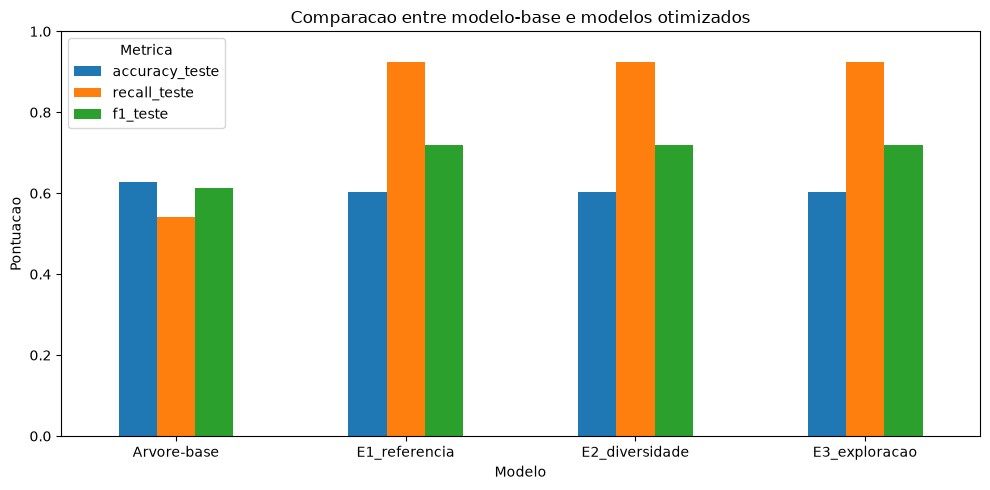

In [12]:
metricas = comparacao.set_index('experimento')[['accuracy_teste', 'recall_teste', 'f1_teste']]
ax = metricas.plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title('Comparacao entre modelo-base e modelos otimizados')
ax.set_xlabel('Modelo')
ax.set_ylabel('Pontuacao')
ax.legend(title='Metrica')
plt.tight_layout()
plt.show()

## 7. Evolucao do fitness

O grafico permite mostrar no video como a busca evoluiu a cada geracao.

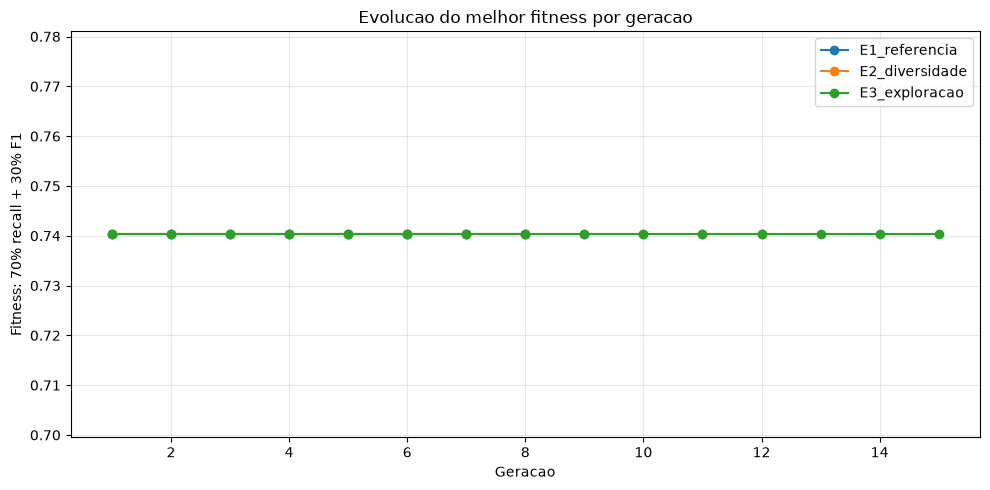

In [13]:
historico = pd.read_csv(DIRETORIO_RESULTADOS / 'historico_ag.csv')
figura, eixo = plt.subplots(figsize=(10, 5))
for experimento, dados_experimento in historico.groupby('experimento'):
    eixo.plot(
        dados_experimento['geracao'],
        dados_experimento['melhor_fitness'],
        marker='o',
        label=experimento,
    )
eixo.set_title('Evolucao do melhor fitness por geracao')
eixo.set_xlabel('Geracao')
eixo.set_ylabel('Fitness: 70% recall + 30% F1')
eixo.legend()
eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Interpretacao com LLM

A celula abaixo usa uma LLM local pelo Ollama: ela nao precisa de chave nem de creditos de API. Antes de executar, instale o Ollama e baixe o modelo com `ollama pull llama3.2:3b`. Somente metricas agregadas sao enviadas.

As instrucoes, o prompt e os criterios de avaliacao estao documentados em `docs/15-integracao-llm.md`.

In [14]:
print('A chave deve ser configurada fora do notebook, na variavel OPENAI_API_KEY do Windows.')

Chave configurada apenas para esta sessao do notebook.


In [1]:
from pathlib import Path
import sys
import pandas as pd

raiz_projeto = Path.cwd().resolve()
if not (raiz_projeto / 'src').exists():
    raiz_projeto = raiz_projeto.parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import importlib
import src.interpretacao_llm as interpretacao_llm
importlib.reload(interpretacao_llm)
gerar_interpretacao_ollama = interpretacao_llm.gerar_interpretacao_ollama

# Carrega a comparacao ja salva, sem reexecutar o algoritmo genetico.
if 'comparacao' not in globals():
    comparacao = pd.read_csv(raiz_projeto / 'resultados' / 'comparacao_modelos.csv')


melhor_linha = comparacao.sort_values(
    ['recall_teste', 'f1_teste'], ascending=False
).iloc[0]
hiperparametros = {
    chave: melhor_linha[chave]
    for chave in ['max_depth', 'min_samples_split', 'min_samples_leaf', 'criterion', 'class_weight']
    if chave in melhor_linha.index and pd.notna(melhor_linha[chave])
}

resumo_llm = {
    'modelo': melhor_linha['experimento'],
    'hiperparametros': hiperparametros,
    'accuracy': melhor_linha['accuracy_teste'],
    'recall': melhor_linha['recall_teste'],
    'f1_score': melhor_linha['f1_teste'],
}

interpretacao = gerar_interpretacao_ollama(resumo_llm, modelo='llama3.2:3b')
print(f'Modo: {interpretacao.modo}')
print('\nPrompt enviado:')
print(interpretacao.prompt)
print('\nInterpretacao:')
print(interpretacao.texto)

Modo: ollama_local

Prompt enviado:
Explique o resultado agregado abaixo em ate tres paragrafos curtos:

Modelo: E1_referencia
Hiperparametros: {'max_depth': np.int64(3), 'min_samples_split': np.float64(2.0), 'min_samples_leaf': np.float64(1.0), 'criterion': 'gini'}
Accuracy: 0.6028
Recall: 0.9235680408609996
F1-score: 0.7182579089232515
Contexto: previsao estatistica de reincidencia para apoio a triagem.


Interpretacao:
O resultado do modelo de classificação E1_referência apresenta uma precisão de 60,28% na previsão de reincidência. Isso significa que, em 60,28% dos casos, o modelo previu corretamente a reincidência do indivíduo.

O modelo também apresentou um excelente desempenho em termos de recall, ou seja, a capacidade de detectar indivíduos que realmente cometeram reincidência. Nesse caso, o recall é de 92,36%, o que indica que o modelo identificou corretamente a reincidência em 92,36% dos casos.

É importante notar que o modelo não é infalível e que a precisão pode variar depen